In [ ]:
!pip install -q pycolmap torchmetrics gsplat
!pip install -q git+https://github.com/compphoto/Intrinsic.git
!pip install -q opencv-python

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [ ]:
!pip install gsplat

  Using cached gsplat-1.5.3-py3-none-any.whl.metadata (1.1 kB)
Using cached gsplat-1.5.3-py3-none-any.whl (6.5 MB)


In [ ]:
import os

try:
    from google.colab import drive
    os.chdir('/content')
    drive.mount('/content/drive', force_remount=True)

    !pip install -q git+https://github.com/compphoto/Intrinsic.git
    !pip install opencv-python
    os.chdir('/content/drive/MyDrive/3dgs_decomposition')
except ModuleNotFoundError:
    pass  # running locally, already in project root

Mounted at /content/drive
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [ ]:

import argparse, glob, os
import numpy as np, torch
import torch.nn.functional as F
from PIL import Image
from gsplat import rasterization
from gsplat.strategy import DefaultStrategy
from torchmetrics.functional import structural_similarity_index_measure as ssim_fn
import os

dev = "cuda"

def get_image_paths(root):
  img_dir = os.path.join(root, "images_8")
  paths = []
  for path in os.listdir(img_dir):
    if (path.endswith(".JPG") or path.endswith(".jpg")):
      paths.append(os.path.join(img_dir, path))

  return paths

import pycolmap

def getw2c(image):
    cam_from_world = image.cam_from_world
    if callable(cam_from_world):
        cam_from_world = cam_from_world()

    w2c = np.eye(4)
    w2c[:3, :4] = np.asarray(cam_from_world.matrix(), dtype=np.float64)
    return w2c

def get_cameras(root, paths):
  colmap_dir = os.path.join(root, "sparse/0")

  reconstruction = pycolmap.Reconstruction(colmap_dir)
  cameras = _as_dict(reconstruction.cameras)

  w2c_mats = []
  camera_ids = []
  by_name = {}

  images = _as_dict(reconstruction.images)
  image_ids = [int(image_id) for image_id in reconstruction.reg_image_ids()]
  imdata = {image_id: images[image_id] for image_id in image_ids}


  for image_id in imdata:
    im = imdata[image_id]
    w2c_mats.append(getw2c(im))
    camera_ids.append(im.camera_id)
    by_name[im.name] = (getw2c(im), int(im.camera_id))


  width, height = Image.open(paths[0]).size
  viewmats = []
  intrinsics = []
  for path in paths:
    name = os.path.basename(path)
    w2c, camera_id = by_name[name]
    cam = cameras[camera_id]
    K = np.asarray(cam.calibration_matrix(), dtype=np.float64).copy()
    K[0, :] *= width / cam.width
    K[1, :] *= height / cam.height

    intrinsics.append(K)
    viewmats.append(w2c)

  points = np.array([p.xyz for p in reconstruction.points3D.values()], dtype=np.float32)

  return (np.stack(viewmats), np.stack(intrinsics), (width, height), points,)


In [ ]:
def _as_dict(map_like):
    return {int(k): v for k, v in map_like.items()}

In [53]:
import pycolmap

In [ ]:
def get_views(paths, root, predictor, dataset, scene):

  images = []
  albedos = []
  depths = []

  for p in paths:
    file_name = os.path.basename(p).split('.')[0]
    print(file_name)
    i = torch.tensor(np.array(Image.open(p).convert("RGB")), dtype=torch.float32) / 255
    width, height = Image.open(p).size


    assert i.ndim == 3 and i.shape[2] == 3, (
            f"Expected (H, W, 3) for {p}, got {tuple(i.shape)}"
        )


    albedo_path = os.path.join(root, predictor, dataset, scene, "albedos", f"{file_name}.npy")
    albedo = torch.tensor(np.load(albedo_path), dtype=torch.float32)
    albedos.append(albedo)

    depth_path = os.path.join(root, "depth_anything_v2", "depths", dataset,
                              scene, f"{file_name}.png",
  )

    depth = torch.tensor(
        np.array(Image.open(depth_path), dtype=np.float32), dtype=torch.float32
    )

    depth_npy_path = os.path.splitext(depth_path)[0] + ".npy"
    np.save(depth_npy_path, depth.detach().cpu().numpy())

    depths.append(depth.detach().clone())
    images.append(i)

  return torch.stack(images).to(dev), torch.stack(albedos).to(dev), torch.stack(depths).to(dev)


In [ ]:
def pearson_loss(d, m):
    d, m = d.flatten(), m.flatten()
    d = (d - d.mean()) / (d.std() + 1e-6); m = (m - m.mean()) / (m.std() + 1e-6)
    return 1 - (d * m).mean()

def photo_loss(pred, tgt, lam=0.2):
    if pred.ndim == 4 and pred.shape[0] == 1:
        pred = pred.squeeze(0)

    if tgt.ndim == 4 and tgt.shape[0] == 1:
        tgt = tgt.squeeze(0)
    l1 = (pred - tgt).abs().mean()
    pred = pred.permute(2, 0, 1).unsqueeze(0)
    tgt = tgt.permute(2, 0, 1).unsqueeze(0)

    s = 1 - ssim_fn(pred, tgt)

    return (1 - lam) * l1 + lam * s

def tv(x):
    return (x[1:] - x[:-1]).abs().mean() + (x[:, 1:] - x[:, :-1]).abs().mean()

In [ ]:

learning_rates = {
    "means": 1.6e-4,
    "scales": 5e-3,
    "quats": 1e-3,
    "opacities": 5e-2,
    "colors": 1e-2,
}

def create_gaussians(means, scales, quats, opacities, colors, scene_scale=1.0):
    params = torch.nn.ParameterDict({
        "means": torch.nn.Parameter(means),
        "scales": torch.nn.Parameter(scales),
        "quats": torch.nn.Parameter(quats),
        "opacities": torch.nn.Parameter(opacities),
        "colors": torch.nn.Parameter(colors),
    })
    optimizers = {
        "means": torch.optim.Adam([params["means"]], lr=learning_rates["means"] * scene_scale),
        "scales": torch.optim.Adam([params["scales"]], lr=learning_rates["scales"]),
        "quats": torch.optim.Adam([params["quats"]], lr=learning_rates["quats"]),
        "opacities": torch.optim.Adam([params["opacities"]], lr=learning_rates["opacities"]),
        "colors": torch.optim.Adam([params["colors"]], lr=learning_rates["colors"]),
    }
    return params, optimizers

In [ ]:
from scipy.spatial import cKDTree

def initialise_gaussians(raw_points, init_scale=1.0, init_opacity=0.1, scene_scale=1.0, dev=dev):
    pts_cpu = np.asarray(raw_points, dtype=np.float32)

    tree = cKDTree(pts_cpu)

    distances, _ = tree.query(pts_cpu, k=4)

    average_distance = np.maximum(distances[:, 1:].mean(axis=-1), 1e-4)

    points = torch.as_tensor(pts_cpu, dtype=torch.float32, device=dev)
    average_distance = torch.as_tensor(average_distance, dtype=torch.float32, device=dev)
    N = len(points)

    scales = torch.log(average_distance * init_scale).unsqueeze(-1).repeat(1, 3)
    quats = F.normalize(torch.rand((N, 4), device=dev), dim=-1)
    opacities = torch.logit(torch.full((N,), init_opacity, device=dev))
    colors = torch.zeros((N, 3), device=dev)


    return create_gaussians(points, scales, quats, opacities, colors, scene_scale=scene_scale)

In [ ]:
def initialise_from_albedos(checkpoint, color_shape, initial_color=0.0):
  means = checkpoint["means"].to(dev).clone()
  scales = checkpoint["scales"].to(dev).clone()
  quats = checkpoint["quats"].to(dev).clone()
  opacities = checkpoint["opacities"].to(dev).clone()

  num_gaussians = len(means)
  colors = torch.full((num_gaussians, *color_shape), initial_color, device=dev)

  return create_gaussians(means, scales, quats, opacities, colors)


In [ ]:
def render_gaussians(gaussians, viewmat, K, width, height, render_mode="RGB",
                     sh_degree=None, color_activation=None, verbose=False):
    means = gaussians["means"]
    quats = gaussians["quats"]
    scales = torch.exp(gaussians["scales"])
    opacities = torch.sigmoid(gaussians["opacities"])
    raw_colors = gaussians["colors"]
    colors = color_activation(raw_colors) if color_activation is not None else raw_colors

    if verbose:  # otherwise this prints every iteration
        print(f"[render_gaussians] N={means.shape[0]}, colors={tuple(colors.shape)}, "
              f"hw=({height},{width}), mode={render_mode}, sh_degree={sh_degree}")

    rendered_colors, rendered_alphas, info = rasterization(
        means=means, quats=quats, scales=scales, opacities=opacities, colors=colors,
        viewmats=viewmat.unsqueeze(0), Ks=K.unsqueeze(0),
        width=width, height=height,
        sh_degree=sh_degree, render_mode=render_mode,
        packed=False,   # strategy expects [C,N,2] means2d/radii
    )
    return rendered_colors[0], rendered_alphas[0], info

albdo = torch.sigmoid
shdo = F.softplus
resdo = lambda c: c

In [ ]:
def step(loss, optimizers, strategy=None, state=None, params=None, step_idx=0, info=None):
    loss.backward()
    if strategy is not None:
      strategy.step_post_backward(
            params=params,
            optimizers=optimizers,
            state=state,
            step=step_idx,
            info=info,
        )
    for optimizer in optimizers.values():
        optimizer.step()
        optimizer.zero_grad(set_to_none=True)


def save_checkpoint(params, checkpoint_directory, scene, predictor):
    os.makedirs(checkpoint_directory, exist_ok=True)
    path = os.path.join(checkpoint_directory, f"{scene}_{predictor}.pt")
    checkpoint = {name: tensor.detach().cpu() for name, tensor in params.items()}
    torch.save(checkpoint, path)
    print("Saved to: " + path)

def load_checkpoint(path):
  return {k: v.to(dev) for k, v in torch.load(path).items()}

In [ ]:
import os
import numpy as np
from PIL import Image
import torch
import torch.nn.functional as F
from gsplat import rasterization


def _tensor_gib(t: torch.Tensor) -> float:
  return t.numel() * t.element_size() / (1024**3)


def get_views(paths, root, predictor, dataset, scene, store_device="cpu"):
  images = []
  albedos = []
  depths = []

  for idx, p in enumerate(paths):
    file_name = os.path.basename(p).split(".")[0]

    with Image.open(p) as img:
      width, height = img.size
      rgb = np.asarray(img.convert("RGB"), dtype=np.float32) / 255.0

    i = torch.from_numpy(rgb)
    assert i.ndim == 3 and i.shape[2] == 3, (
        f"Expected (H, W, 3) for {p}, got {tuple(i.shape)}"
    )

    albedo_path = os.path.join(
        root, predictor, dataset, scene, "albedos", f"{file_name}.npy"
    )
    albedo = torch.from_numpy(np.asarray(np.load(albedo_path), dtype=np.float32))

    depth_path = os.path.join(
        root, "depth_anything_v2", "depths", dataset, scene, f"{file_name}.png"
    )
    with Image.open(depth_path) as d_img:
      depth_np = np.asarray(d_img, dtype=np.float32)

    depth = torch.from_numpy(depth_np)
    depth_npy_path = os.path.splitext(depth_path)[0] + ".npy"
    np.save(depth_npy_path, depth_np)

    images.append(i.to(store_device))
    albedos.append(albedo.to(store_device))
    depths.append(depth.detach().clone().to(store_device))

  stacked_images = torch.stack(images, dim=0)
  stacked_albedos = torch.stack(albedos, dim=0)
  stacked_depths = torch.stack(depths, dim=0)

  return stacked_images, stacked_albedos, stacked_depths

In [54]:
PROJECT = "/content/drive/MyDrive/3dgs_decomposition"
dataset, scene, predictor = "mipnerf360", "room", "rgbx"
SCENE_ROOT = f"{PROJECT}/data/{dataset}/{scene}"
CKPT = f"{PROJECT}/ckpt"

paths = sorted(get_image_paths(SCENE_ROOT))[:2]
viewmats, intrinsics, (width, height), points = get_cameras(SCENE_ROOT, paths)
images, albedos, depths = get_views(paths, PROJECT, predictor, dataset, scene)

print(len(paths), "views,", width, "x", height, ",", len(points), "points")
print(images.shape, albedos.shape, depths.shape)

2 views, 389 x 259 , 112627 points
torch.Size([2, 259, 389, 3]) torch.Size([2, 259, 389, 3]) torch.Size([2, 259, 389])


In [ ]:
!cp -r /root/.cache/torch_extensions /content/drive/MyDrive/3dgs/torch_ext_cache


In [ ]:
!mkdir -p /root/.cache && cp -r /content/drive/MyDrive/3dgs/torch_ext_cache /root/.cache/torch_extensions


In [ ]:
def to_dev(a):
    return torch.tensor(np.asarray(a), dtype=torch.float32, device=dev)

In [ ]:
def fit_albedo(points, viewmats, intrinsics, width, height, images, albedos, depths, scene, predictor, ckpt_dir, iters=7000, lam_depth=0.1):
    viewmats = torch.as_tensor(viewmats, dtype=torch.float32, device=dev)
    intrinsics = torch.as_tensor(intrinsics, dtype=torch.float32, device=dev)
    images = torch.as_tensor(images, dtype=torch.float32, device=dev)
    albedos = torch.as_tensor(albedos, dtype=torch.float32, device=dev)
    depths = torch.as_tensor(depths, dtype=torch.float32, device=dev)

    if albedos.max().item() > 1.5:
        albedos = albedos / 255.0

    params, optimizers = initialise_gaussians(points)
    strategy = DefaultStrategy(verbose=False)
    strategy.check_sanity(params, optimizers)
    state = strategy.initialize_state()

    for it in range(iters):
        v = np.random.randint(len(images))
        target_albedo = albedos[v:v+1].to(dev)
        target_depth = depths[v:v+1].to(dev)
        out, alphas, info = render_gaussians(params, viewmats[v], intrinsics[v], width, height, render_mode="RGB+ED", color_activation=albdo)

        out = out.squeeze(0)
        alphas = alphas.squeeze(0)

        pred = out[..., :3]
        depth = out[..., 3]

        strategy.step_pre_backward(params=params, optimizers=optimizers, state=state, step=it, info=info )

        if it == 0:
          print()

        albedo_loss = photo_loss(pred, target_albedo)

        depth_loss = pearson_loss(1.0 / depth.clamp(min=1e-3), target_depth)

        loss = albedo_loss + lam_depth * depth_loss

        step(loss, optimizers, strategy, state, params, it, info)

        del out, alphas, info
        del pred, depth, loss
        del albedo_loss, depth_loss
        del target_albedo, target_depth

    save_checkpoint(params, os.path.join(ckpt_dir, "albedo"), scene, predictor)

    return params

In [ ]:
def freeze_albedo(viewmats, intrinsics, width, height, images, scene, predictor, ckpt_dir,
                iters=3000, lam_tv=0.05):
    viewmats = torch.as_tensor(viewmats, dtype=torch.float32, device=dev)
    intrinsics = torch.as_tensor(intrinsics, dtype=torch.float32, device=dev)
    images = torch.as_tensor(images, dtype=torch.float32, device=dev)

    if (images.max().item() > 1.5):
      images = images/255.0
    path = os.path.join(ckpt_dir, "albedo", f"{scene}_{predictor}.pt")

    albedo_params = load_checkpoint(os.path.join(ckpt_dir, "albedo", f"{scene}_{predictor}.pt"))
    params, optimizers = initialise_from_albedos(albedo_params, (3,), initial_color=0.54)

    for it in range(iters):
      v = np.random.randint(len(images))
      target_image = images[v:v+1].to(dev)

      with torch.no_grad():
        albedo, albedo_alphas, _ = render_gaussians(albedo_params, viewmats[v], intrinsics[v], width, height, color_activation=albdo)
        albedo = albedo.squeeze(0)

      shading, shading_alphas, info = render_gaussians(params, viewmats[v], intrinsics[v], width, height, color_activation=shdo)
      shading = shading.squeeze(0)

      if it == 0:
            print(albedo.shape, shading.shape, target_image.shape)

      photo = photo_loss(albedo * shading, target_image)
      tv_loss = tv(shading)
      loss = photo + lam_tv * tv_loss
      step(loss, optimizers, step_idx=it)
      if it % 500 == 0:
          print(f"B {it}: loss {loss.item():.4f}")

      del albedo, albedo_alphas, shading, shading_alphas, info
      del photo, tv_loss, loss
      del target_image

    save_checkpoint(
        params,
        os.path.join(ckpt_dir, "shading"),
        scene,
        predictor
    )

    return params

In [ ]:
def freeze_albedo_shading(viewmats, intrinsics, width, height, images, scene, predictor, ckpt_dir,
                iters=3000, lam_res=0.05):
    viewmats = torch.as_tensor(viewmats, dtype=torch.float32, device=dev)
    intrinsics = torch.as_tensor(intrinsics, dtype=torch.float32, device=dev)
    images = torch.as_tensor(images, dtype=torch.float32, device=dev)

    if (images.max().item() > 1.5):
      images = images/255.0
    albedo_path = os.path.join(ckpt_dir, "albedo", f"{scene}_{predictor}.pt")
    shading_path = os.path.join(ckpt_dir, "shading", f"{scene}_{predictor}.pt")

    albedo_params = load_checkpoint(os.path.join(ckpt_dir, "albedo", f"{scene}_{predictor}.pt"))
    shading_params = load_checkpoint(os.path.join(ckpt_dir, "shading", f"{scene}_{predictor}.pt"))

    params, optimizers = initialise_from_albedos(albedo_params, (9,3), initial_color=0.0)

    for it in range(iters):
      v = np.random.randint(len(images))
      target_image = images[v:v+1].to(dev)

      with torch.no_grad():
        albedo, albedo_alphas, _ = render_gaussians(albedo_params, viewmats[v], intrinsics[v], width, height, color_activation=albdo)
        albedo = albedo.squeeze(0)
        shading, shading_alphas, info = render_gaussians(shading_params, viewmats[v], intrinsics[v], width, height, color_activation=shdo)
        shading = shading.squeeze(0)

      residuals, residuals_alphas, info = render_gaussians(params, viewmats[v], intrinsics[v], width, height, sh_degree=2, color_activation=resdo)
      residuals = residuals.squeeze(0) - SH_OFFSET * residuals_alphas.squeeze(0)


      if it == 0:
            print(albedo.shape, shading.shape, target_image.shape)

      photo = photo_loss(albedo * shading + residuals, target_image)

      res_loss = residuals.abs().mean()

      loss = photo + lam_res * res_loss

      step(loss, optimizers, step_idx=it)

      if it % 500 == 0:
          print(f"C {it}: loss {loss.item():.4f}")

      del albedo, albedo_alphas, shading, shading_alphas, residuals, residuals_alphas, info
      del photo, res_loss, loss
      del target_image


    save_checkpoint(
        params,
        os.path.join(ckpt_dir, "residual"),
        scene,
        predictor
    )

    return params

In [ ]:
def check_priors_computed(ROOT, path, predictor, dataset, scene):
  image = os.path.splitext(os.path.basename(path))[0]
  if ((os.path.exists(os.path.join(ROOT, predictor, dataset, scene, "albedos", image + ".npy"))) and (os.path.exists(os.path.join(ROOT, "depth_anything_v2", "depths", dataset, scene, image + ".png")))):
        return True
  else:
    return False

In [58]:
def load(ROOT, predictor, dataset, scene):
  path = os.path.join(ROOT, "data", dataset, scene)
  print(path)
  all_paths = get_image_paths(path)[:5]
  paths_with_priors = [p for p in all_paths if check_priors_computed(ROOT, p, predictor, dataset, scene)]
  viewmats, intrinsics, (width, height), points = get_cameras(ROOT + "/data/" + dataset + "/" + scene, paths_with_priors)
  images, albedos, depths = get_views(paths_with_priors, ROOT, predictor, dataset, scene)

  res = {
      "root": ROOT,
      "paths": paths_with_priors,
      "viewmats": viewmats,
      "intrinsics": intrinsics,
      "width": width,
      "height": height,
      "points": points,
      "images": images,
      "albedos": albedos,
      "depths": depths
  }
  return res

In [60]:
def render_layers(albedo_parameters, shading_parameters, residuals_parameters, viewmat, K, width, height):
    albedo, _, _ = render_gaussians(albedo_parameters, viewmat, K, width, height, color_activation=albdo)
    shading, _, _ = render_gaussians(shading_parameters, viewmat, K, width, height, color_activation=shdo)
    residual, r_aux, _ = render_gaussians(residuals_parameters, viewmat, K, width, height, sh_degree=2, color_activation=resdo)
    return albedo, shading, residual - SH_OFFSET * r_aux

def save_preview(path, albedo_parameters, shading_parameters, residuals_parameters, viewmat, K, width, height, image):
    albedo, shading, residual = render_layers(albedo_parameters, shading_parameters, residuals_parameters, viewmat, K, width, height)
    tiles = [image.to(dev), albedo, shading, residual + 0.5, albedo * shading + residual]
    row = torch.cat([t.clamp(0, 1) for t in tiles], dim=1)
    os.makedirs(os.path.dirname(path), exist_ok=True)
    Image.fromarray((row.cpu().numpy() * 255).astype(np.uint8)).save(path)

In [38]:
import tempfile, shutil

SH_OFFSET = 0.5

ROOT = "/content/drive/MyDrive/3dgs_decomposition"

def small_test(scene="room", predictor="rgbx", dataset="mipnerf360", iters=20):
    data = load(ROOT, predictor, dataset, scene)
    W, H = data["width"], data["height"]
    vm, K = data["viewmats"], data["intrinsics"]
    tmp = tempfile.mkdtemp()

    try:
        pts = data["points"][::10]
        fit_albedo(pts, vm, K, W, H, data["images"], data["albedos"], data["depths"],
                   scene, predictor, tmp, iters=iters)
        freeze_albedo(vm, K, W, H, data["images"], scene, predictor, tmp, iters=iters)
        freeze_albedo_shading(vm, K, W, H, data["images"], scene, predictor, tmp, iters=iters)

        A = load_checkpoint(f"{tmp}/albedo/{scene}_{predictor}.pt")
        S = load_checkpoint(f"{tmp}/shading/{scene}_{predictor}.pt")
        R = load_checkpoint(f"{tmp}/residual/{scene}_{predictor}.pt")

        a, s, r = render_layers(A, S, R, to_dev(vm)[0], to_dev(K)[0], W, H)
        full = a * s + r
        assert full.shape == (H, W, 3), f"bad render shape {tuple(full.shape)}"
        assert torch.isfinite(full).all(), "A*S+R contains NaN/inf"
        print(f"PASS: {len(A['means'])} Gaussians, A*S+R mean {full.mean():.3f}, "
              f"photo mean {data['images'][0].mean():.3f}")
    finally:
        shutil.rmtree(tmp, ignore_errors=True)

small_test()

/content/drive/MyDrive/3dgs_decomposition/data/mipnerf360/room



/usr/local/lib/python3.13/dist-packages/torchmetrics/utilities/prints.py:70: FutureWarning: Importing `spectral_angle_mapper` from `torchmetrics.functional` was deprecated and will be removed in 2.0. Import `spectral_angle_mapper` from `torchmetrics.image` instead.
  _future_warning(


Saved to: /tmp/tmppv0n6v7m/albedo/room_rgbx.pt
torch.Size([259, 389, 3]) torch.Size([259, 389, 3]) torch.Size([1, 259, 389, 3])
B 0: loss 0.3706
Saved to: /tmp/tmppv0n6v7m/shading/room_rgbx.pt
torch.Size([259, 389, 3]) torch.Size([259, 389, 3]) torch.Size([1, 259, 389, 3])
C 0: loss 0.2568
Saved to: /tmp/tmppv0n6v7m/residual/room_rgbx.pt
PASS: 11263 Gaussians, A*S+R mean 0.215, photo mean 0.229


In [61]:
CHECKPOINT_ROOT = TEST_CKPT

fit_albedo(points[::10], viewmats, intrinsics, width, height, images, albedos, depths,
           scene, predictor, TEST_CKPT, iters=50)
freeze_albedo(viewmats, intrinsics, width, height, images, scene, predictor, TEST_CKPT, iters=50)
freeze_albedo_shading(viewmats, intrinsics, width, height, images, scene, predictor, TEST_CKPT, iters=50)

# Load from the correct paths where they were saved
A = load_checkpoint(os.path.join(CHECKPOINT_ROOT, "albedo", f"{scene}_{predictor}.pt"))
S = load_checkpoint(os.path.join(CHECKPOINT_ROOT, "shading", f"{scene}_{predictor}.pt"))
R = load_checkpoint(os.path.join(CHECKPOINT_ROOT, "residual", f"{scene}_{predictor}.pt"))

a, s, r = render_layers(A, S, R, to_dev(viewmats)[0], to_dev(intrinsics)[0], width, height)
full = a * s + r
print("finite:", torch.isfinite(full).all().item(), "| shape:", tuple(full.shape))
print(f"A*S+R mean {full.mean():.3f}  vs  photo mean {images[0].mean():.3f}")

save_preview("/content/preview.png", A, S, R, to_dev(viewmats)[0], to_dev(intrinsics)[0], width, height, images[0])

/usr/local/lib/python3.13/dist-packages/torchmetrics/utilities/prints.py:70: FutureWarning: Importing `spectral_angle_mapper` from `torchmetrics.functional` was deprecated and will be removed in 2.0. Import `spectral_angle_mapper` from `torchmetrics.image` instead.
  _future_warning(


Saved to: /content/drive/MyDrive/3dgs_decomposition/albedo/room_rgbx.pt
torch.Size([259, 389, 3]) torch.Size([259, 389, 3]) torch.Size([1, 259, 389, 3])
B 0: loss 0.3496
Saved to: /content/drive/MyDrive/3dgs_decomposition/shading/room_rgbx.pt
torch.Size([259, 389, 3]) torch.Size([259, 389, 3]) torch.Size([1, 259, 389, 3])
C 0: loss 0.1597
Saved to: /content/drive/MyDrive/3dgs_decomposition/residual/room_rgbx.pt
finite: True | shape: (259, 389, 3)
A*S+R mean 0.229  vs  photo mean 0.229


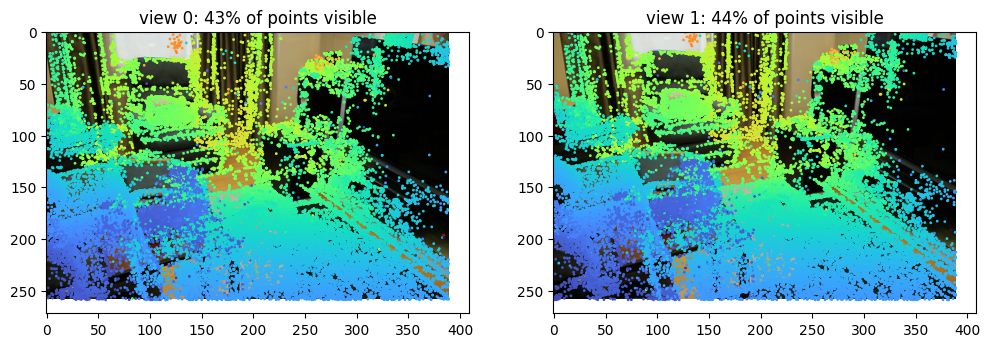

In [ ]:
import matplotlib.pyplot as plt

vm, K = to_dev(viewmats), to_dev(intrinsics)
P = torch.tensor(points, dtype=torch.float32, device=dev)

fig, ax = plt.subplots(1, len(paths), figsize=(6 * len(paths), 4))
ax = np.atleast_1d(ax)
for v in range(len(paths)):
    cam = P @ vm[v, :3, :3].T + vm[v, :3, 3]          # world -> camera
    z = cam[:, 2]
    uv = cam @ K[v].T                                  # camera -> pixels
    u, w = uv[:, 0] / z.clamp(min=1e-6), uv[:, 1] / z.clamp(min=1e-6)
    m = (z > 0) & (u >= 0) & (u < width) & (w >= 0) & (w < height)
    ax[v].imshow(images[v].cpu())
    ax[v].scatter(u[m].cpu(), w[m].cpu(), s=1, c=z[m].cpu(), cmap="turbo")
    ax[v].set_title(f"view {v}: {m.float().mean():.0%} of points visible")
plt.show()

covered pixels: 100%   correlation: 0.86
depth PNG range: 0 to 65535


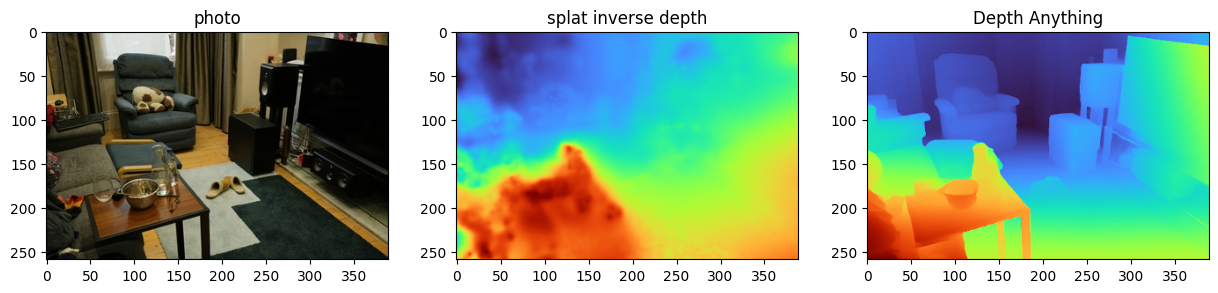

In [ ]:
v = 0
params0, _ = initialise_gaussians(points[::4])
with torch.no_grad():
    out, alpha, _ = render_gaussians(params0, vm[v], K[v], width, height,
                                     render_mode="RGB+ED", color_activation=albdo)
mask = alpha[..., 0] > 0.05                            # pixels the Gaussians actually cover
inv = 1.0 / out[..., 3].clamp(min=1e-3)                # rendered INVERSE depth
da = depths[v].to(dev)

corr = torch.corrcoef(torch.stack([inv[mask], da[mask]]))[0, 1].item()
print(f"covered pixels: {mask.float().mean():.0%}   correlation: {corr:.2f}")
print(f"depth PNG range: {depths.min():.0f} to {depths.max():.0f}")

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].imshow(images[v].cpu());                                         ax[0].set_title("photo")
ax[1].imshow(torch.where(mask, inv, torch.zeros_like(inv)).cpu(), cmap="turbo"); ax[1].set_title("splat inverse depth")
ax[2].imshow(da.cpu(), cmap="turbo");                                  ax[2].set_title("Depth Anything")
plt.show()

In [48]:
v0 = slice(0, 1)
TEST_CKPT = "/content/drive/MyDrive/3dgs_decomposition/"                       # scratch folder, not your real CKPT
vm0, K0 = to_dev(viewmats)[0], to_dev(intrinsics)[0]
photo = images[0].to(dev)
tgt_a = (albedos[0] / 255 if albedos.max() > 1.5 else albedos[0]).to(dev)
pts = points[::10]

In [62]:
params0, _ = initialise_gaussians(pts)                  # untrained Gaussians
fit_albedo(pts, viewmats[v0], intrinsics[v0], width, height,
           images[v0], albedos[v0], depths[v0], scene, predictor, TEST_CKPT, iters=200)

A = load_checkpoint(os.path.join(CHECKPOINT_ROOT, "albedo", scene + "_" + predictor +".pt"))

with torch.no_grad():
    before = photo_loss(render_gaussians(params0, vm0, K0, width, height, color_activation=albdo)[0], tgt_a).item()
    after  = photo_loss(render_gaussians(A,       vm0, K0, width, height, color_activation=albdo)[0], tgt_a).item()
print(f"A: {before:.4f} -> {after:.4f}")

/usr/local/lib/python3.13/dist-packages/torchmetrics/utilities/prints.py:70: FutureWarning: Importing `spectral_angle_mapper` from `torchmetrics.functional` was deprecated and will be removed in 2.0. Import `spectral_angle_mapper` from `torchmetrics.image` instead.
  _future_warning(


Saved to: /content/drive/MyDrive/3dgs_decomposition/albedo/room_rgbx.pt
A: 0.3116 -> 0.0563


In [63]:
freeze_albedo(viewmats[v0], intrinsics[v0], width, height, images[v0], scene, predictor, TEST_CKPT, iters=200)
S = load_checkpoint(f"{CHECKPOINT_ROOT}/shading/{scene}_{predictor}.pt")

with torch.no_grad():
    A_i = render_gaussians(A, vm0, K0, width, height, color_activation=albdo)[0]
    S_i = render_gaussians(S, vm0, K0, width, height, color_activation=shdo)[0]
print(f"B: {photo_loss(A_i, photo).item():.4f} -> {photo_loss(A_i * S_i, photo).item():.4f}")   # S starts at ~1

torch.Size([259, 389, 3]) torch.Size([259, 389, 3]) torch.Size([1, 259, 389, 3])
B 0: loss 0.3518
Saved to: /content/drive/MyDrive/3dgs_decomposition/shading/room_rgbx.pt
B: 0.3789 -> 0.0363


In [64]:
freeze_albedo_shading(viewmats[v0], intrinsics[v0], width, height, images[v0], scene, predictor, TEST_CKPT, iters=200)
R = load_checkpoint(f"{CHECKPOINT_ROOT}/residual/{scene}_{predictor}.pt")

a, s, r = render_layers(A, S, R, vm0, K0, width, height)
print(f"C: {photo_loss(a * s, photo).item():.4f} -> {photo_loss(a * s + r, photo).item():.4f}")

torch.Size([259, 389, 3]) torch.Size([259, 389, 3]) torch.Size([1, 259, 389, 3])
C 0: loss 0.0363
Saved to: /content/drive/MyDrive/3dgs_decomposition/residual/room_rgbx.pt
C: 0.0363 -> 0.0178
